# Lab 1 - Hierarchical Clustering
## JS08 - Hierarchical Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097

This notebook groups retail customers using Annual Income and Spending Score, then evaluates the Agglomerative Clustering result.

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


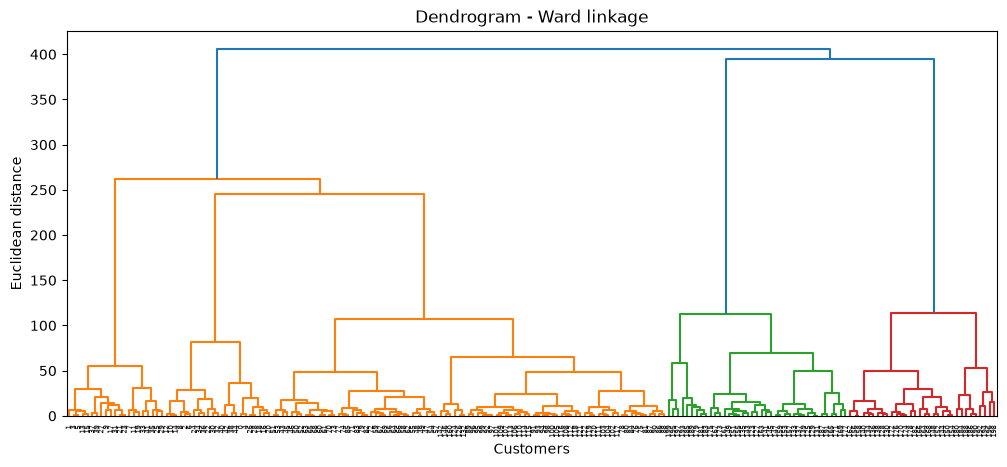

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

df = pd.read_csv('Mall_Customers.csv')
display(df.head())
df.info()
X = df.iloc[:, [3, 4]].to_numpy()

plt.figure(figsize=(12, 5))
sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram - Ward linkage')
plt.xlabel('Customers')
plt.ylabel('Euclidean distance')
plt.show()

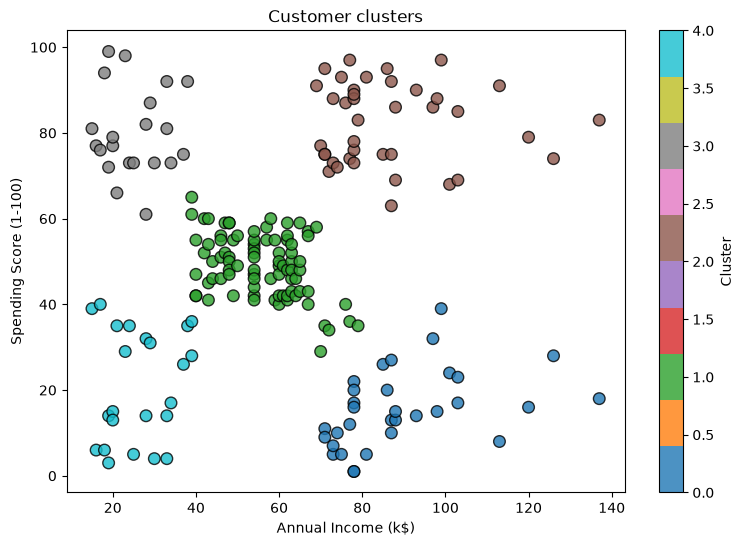

Silhouette Coefficient: 0.5530
Cluster sizes:


Cluster
1    32
2    85
3    39
4    21
5    23
Name: customers, dtype: int64

In [2]:
hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
labels = hc.fit_predict(X)
df['Cluster'] = labels + 1

plt.figure(figsize=(9, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=70, edgecolor='black', alpha=0.8)
plt.title('Customer clusters')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.colorbar(label='Cluster')
plt.show()

silhouette_avg = silhouette_score(X, labels)
print(f'Silhouette Coefficient: {silhouette_avg:.4f}')
print('Cluster sizes:')
display(df['Cluster'].value_counts().sort_index().rename('customers'))

### Conclusion
The dendrogram supports five practical groups for this exercise. A silhouette score close to 1 indicates well-separated groups; the score printed above provides the measurable assessment for this dataset. Cluster labels are identifiers only and do not imply an ordering.